# B03 缺失、重复和异常数据应该怎样处理？

使用含脏值的传感器记录，制作逐项可追踪的清洗规则。展示缺测与异常的差别，并使用只看过去的填充，避免时间泄漏。

先修：B01—B02；布尔条件、缺失值、copy 与按条件赋值。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 保留原始输入
原始文件不可被清洗覆盖。先展示缺陷：非法文本、重复时间和超出物理范围的读数。`errors="coerce"` 把无法转换的项变成缺失，但必须同时记录数量。

In [2]:
import pandas as pd, numpy as np, json
raw = pd.read_csv(DATA_DIR / 'sensor_dirty.csv')
work = raw.copy()
work['time'] = pd.to_datetime(work['time'], errors='coerce')
work['temperature'] = pd.to_numeric(work['temperature'], errors='coerce')
report = {'input_rows': len(raw), 'invalid_time': int(work['time'].isna().sum()), 'unparseable_or_missing': int(work['temperature'].isna().sum())}
print(work)


                 time  temperature
0 2024-07-01 00:00:00         20.0
1 2024-07-01 01:00:00         21.0
2 2024-07-01 01:00:00         22.0
3 2024-07-01 02:00:00          NaN
4 2024-07-01 03:00:00         24.0
5 2024-07-01 04:00:00        999.0
6 2024-07-01 05:00:00          NaN
7 2024-07-01 06:00:00         26.0


## 2. 定义行的身份与规则
本题规定同一时间重复上传以最后一条为准。这是业务假设，不是所有任务的通用处理。先排序再去重，并保留修改标记；物理异常置缺失而非直接删除整天。

In [3]:
work = work.dropna(subset=['time']).sort_values('time', kind='stable')
report['duplicate_rows'] = int(work.duplicated('time', keep='last').sum())
work = work.drop_duplicates('time', keep='last').copy()
work['out_of_range'] = ~work['temperature'].between(-40, 60) & work['temperature'].notna()
report['range_violations'] = int(work['out_of_range'].sum())
work.loc[work['out_of_range'], 'temperature'] = np.nan


## 3. 填充只使用过去：留下可追查标志
这里最多向前填 1 个点，连续长缺测不能伪造平滑曲线。`ffill` 只使用已观测历史；本例不做双向插值。删除无法处理的开头缺测时计入报告。

In [4]:
work['was_missing'] = work['temperature'].isna()
work['temperature_clean'] = work['temperature'].ffill(limit=1)
report['remaining_missing'] = int(work['temperature_clean'].isna().sum())
clean = work.dropna(subset=['temperature_clean']).copy()
assert clean['time'].is_unique
assert clean['temperature_clean'].between(-40, 60).all()
assert report['duplicate_rows'] == 1


## 4. 输出清洗日志，而不只交一张干净表
清洗报告告诉使用者保留了多少记录、改动了哪些值。图中的空缺和填充值应能对应审计列；需要训练模型时，统计型填充值仍须只在训练集估计。

In [5]:
report['output_rows'] = len(clean)
clean.to_csv(OUT_DIR / 'clean.csv', index=False, encoding='utf-8-sig')
work.to_csv(OUT_DIR / 'audit.csv', index=False, encoding='utf-8-sig')
(OUT_DIR / 'metrics.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
plt.plot(work['time'], work['temperature'], 'o', label='有效原值')
plt.plot(work['time'], work['temperature_clean'], '--', label='单步前向填充')
plt.legend(); plt.ylabel('温度 / °C'); plt.xticks(rotation=25); plt.tight_layout()
plt.savefig(OUT_DIR / 'cleaning.png'); plt.close(); print(report)


{'input_rows': 8, 'invalid_time': 0, 'unparseable_or_missing': 2, 'duplicate_rows': 1, 'range_violations': 1, 'remaining_missing': 1, 'output_rows': 6}

## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

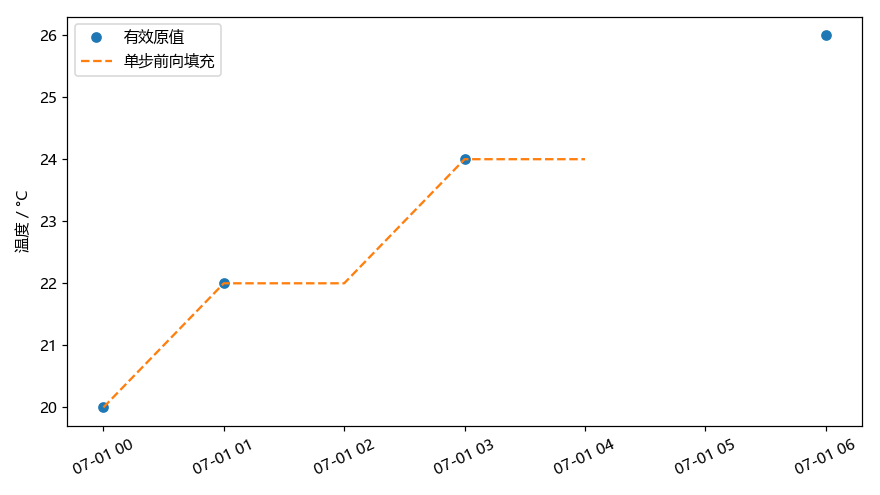

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
异常不一定是传感器坏了；实际规则应由测量范围与业务解释支持。此处只演示一条明确的教学规则。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。